# mpstab against an exact reference at 100 qubits

The kicked transverse-field Ising Floquet circuit

$$U = \Big[\prod_{\langle i,i+1\rangle} R_{XX}(\theta_J)\Big]\Big[\prod_i R_Z(\theta_h)\Big] \quad\text{repeated } T \text{ times}$$

is a matchgate (free-fermion) circuit. Under the Jordan–Wigner transform every
gate rotates a pair of Majorana modes, $|0\dots0\rangle$ is a Gaussian state,
and any Pauli expectation follows from the $2n\times 2n$ Majorana covariance
matrix by Wick's theorem. That gives **exact values at any width and depth** in
$O(n^3)$, against which mpstab can be checked far beyond statevector sizes.

**The magic knob**: $\theta_h = 0$ is Clifford, $\pi/8$ low magic, $\pi/4$
T-like; $\theta_J = \pi/2$ keeps the couplings Clifford, any other value makes
them magic too.

**Caveat**: free fermions are also easy for Pauli propagation (a Majorana
bilinear stays a bilinear), so this notebook certifies accuracy at scale, not
an advantage. For that see `echo.ipynb`.

**Launch** from the repository root:

```bash
uv run --with juliacall --with pandas --with jupyterlab jupyter lab examples/notebooks/benchmarks/
```

The PauliPropagation.jl cells download Julia and the package on first use (a
few minutes); everything else needs only mpstab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from qibo import Circuit, gates, set_backend

import frameworks as fw
from mpstab.evolutors.utils import gate_angle, gate_generator

set_backend("numpy")
COLORS = ["#2a78d6", "#6250d6", "#1f4f8f", "#1baf7a", "#008300"]

[Qibo 0.3.6|INFO|2026-11-17 09:54:27]: Using numpy backend on /CPU:0


## The exact reference

Majoranas $c_{2i} = Z_0\cdots Z_{i-1}X_i$ and $c_{2i+1} = Z_0\cdots Z_{i-1}Y_i$,
so $Z_i = -i\,c_{2i}c_{2i+1}$ and $X_iX_{i+1} = -i\,c_{2i+1}c_{2i+2}$. A gate
$e^{-i\theta G/2}$ with $G = i s\, c_a c_b$ rotates $(c_a, c_b)$ by $s\theta$ in
the Heisenberg picture, and the covariance
$\Gamma_{ab} = \tfrac{i}{2}\langle[c_a, c_b]\rangle$ transforms as
$\Gamma \to R\,\Gamma R^T$. Then
$\langle c_{a_1}\cdots c_{a_{2k}}\rangle = \mathrm{Pf}(-i\,\Gamma_{\{a\}})$.

In [2]:
def floquet_circuit(n, steps, theta_h, theta_j=np.pi / 2):
    """RZ(theta_h) on every qubit, then RXX(theta_j) on every bond, `steps` times."""
    circuit = Circuit(n)
    for _ in range(steps):
        for q in range(n):
            circuit.add(gates.RZ(q, theta=theta_h))
        for start in (0, 1):  # even bonds, then odd bonds (they commute)
            for q in range(start, n - 1, 2):
                circuit.add(gates.RXX(q, q + 1, theta=theta_j))
    return circuit


def majorana_form(pauli):
    """pauli = phase * c_{a_1} ... c_{a_m}, with a_1 < ... < a_m."""
    phase, word = 1 + 0j, []
    for i, label in enumerate(pauli):
        if label == "Z":
            phase *= -1j
            word += [2 * i, 2 * i + 1]
        elif label in "XY":
            phase *= (-1j) ** i  # the Jordan-Wigner string Z_0 ... Z_{i-1}
            word += list(range(2 * i)) + [2 * i if label == "X" else 2 * i + 1]
    for end in range(len(word) - 1, 0, -1):  # sort: -1 per swap of distinct modes
        for k in range(end):
            if word[k] > word[k + 1]:
                word[k], word[k + 1] = word[k + 1], word[k]
                phase = -phase
    reduced = []
    for a in word:  # c^2 = 1
        if reduced and reduced[-1] == a:
            reduced.pop()
        else:
            reduced.append(a)
    return phase, reduced


def pfaffian(matrix):
    """Pfaffian of an antisymmetric matrix (pivoted Parlett-Reid)."""
    a = np.array(matrix, dtype=complex)
    n = a.shape[0]
    if n % 2:
        return 0.0
    result = 1.0 + 0j
    for k in range(0, n - 1, 2):
        pivot = k + 1 + int(np.argmax(np.abs(a[k, k + 1 :])))
        if pivot != k + 1:
            a[[k + 1, pivot]] = a[[pivot, k + 1]]
            a[:, [k + 1, pivot]] = a[:, [pivot, k + 1]]
            result = -result
        if a[k, k + 1] == 0:
            return 0.0
        result *= a[k, k + 1]
        if k + 2 < n:
            tau = a[k, k + 2 :] / a[k, k + 1]
            column = a[k + 2 :, k + 1].copy()
            a[k + 2 :, k + 2 :] += np.outer(tau, column) - np.outer(column, tau)
    return result


def covariance_after(circuit):
    """Majorana covariance of circuit|0...0>."""
    n = circuit.nqubits
    gamma = np.zeros((2 * n, 2 * n))
    for i in range(n):  # Z_i = +1  <=>  <c_2i c_2i+1> = i
        gamma[2 * i, 2 * i + 1], gamma[2 * i + 1, 2 * i] = -1.0, 1.0
    for gate in circuit.queue:
        phase, modes = majorana_form(gate_generator(gate, n))
        assert len(modes) == 2, f"{gate.name} is not a free-fermion gate"
        angle = np.sign(phase.imag) * gate_angle(gate)
        rotation = np.array([[np.cos(angle), np.sin(angle)], [-np.sin(angle), np.cos(angle)]])
        gamma[modes, :] = rotation @ gamma[modes, :]
        gamma[:, modes] = gamma[:, modes] @ rotation.T
    return gamma


def exact(gamma, pauli):
    """<pauli> from the covariance, by Wick's theorem."""
    phase, modes = majorana_form(pauli)
    if len(modes) % 2:
        return 0.0  # odd parity vanishes
    value = pfaffian(-1j * gamma[np.ix_(modes, modes)]) if modes else 1.0
    return float((phase * value).real)

### Check against a qibo statevector

Random Pauli strings, including long non-local ones whose Pfaffians are large,
on three circuits with different magic.

In [3]:
rng = np.random.default_rng(0)
n = 8
paulis = ["".join(rng.choice(list("IIIXYZ"), n)) for _ in range(60)]
worst = 0.0
for theta_h, theta_j, steps in [(0.3, np.pi / 2, 3), (np.pi / 4, 0.7, 4), (1.1, -0.4, 5)]:
    circuit = floquet_circuit(n, steps, theta_h, theta_j)
    state, gamma = circuit().state(), covariance_after(circuit)
    for p in paulis:
        if set(p) != {"I"}:
            reference = fw.qibo_hamiltonian(p, n, None).expectation_from_state(state)
            worst = max(worst, abs(exact(gamma, p) - float(np.real(reference))))
print(f"max |free fermions - qibo statevector| over {3 * len(paulis)} strings: {worst:.1e}")

/Users/robbiati/.cache/uv/archive-v0/7Ai9FnySbBq1nKb4NV44c/lib/python3.11/site-packages/qibo/backends/abstract.py:1216: RuntimeWarning: divide by zero encountered in matmul
  return self.engine.matmul(array_1, array_2, **kwargs)
/Users/robbiati/.cache/uv/archive-v0/7Ai9FnySbBq1nKb4NV44c/lib/python3.11/site-packages/qibo/backends/abstract.py:1216: RuntimeWarning: overflow encountered in matmul
  return self.engine.matmul(array_1, array_2, **kwargs)
/Users/robbiati/.cache/uv/archive-v0/7Ai9FnySbBq1nKb4NV44c/lib/python3.11/site-packages/qibo/backends/abstract.py:1216: RuntimeWarning: invalid value encountered in matmul
  return self.engine.matmul(array_1, array_2, **kwargs)
/Users/robbiati/.cache/uv/archive-v0/7Ai9FnySbBq1nKb4NV44c/lib/python3.11/site-packages/qibo/backends/abstract.py:3046: RuntimeWarning: divide by zero encountered in matmul
  hstate = hamiltonian @ state
/Users/robbiati/.cache/uv/archive-v0/7Ai9FnySbBq1nKb4NV44c/lib/python3.11/site-packages/qibo/backends/abstract.py:30

max |free fermions - qibo statevector| over 180 strings: 1.8e-15


## mpstab at 100 qubits

$\langle Z_{n/2}\rangle$ against the exact value, sweeping depth for three
magic levels and three bond dimensions. Without truncation mpstab is exact; the
error comes from the bond-dimension cap $\chi$ once the light cone's
entanglement outgrows it.

/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


theta_h=0.196 done


theta_h=0.393 done


theta_h=0.785 done


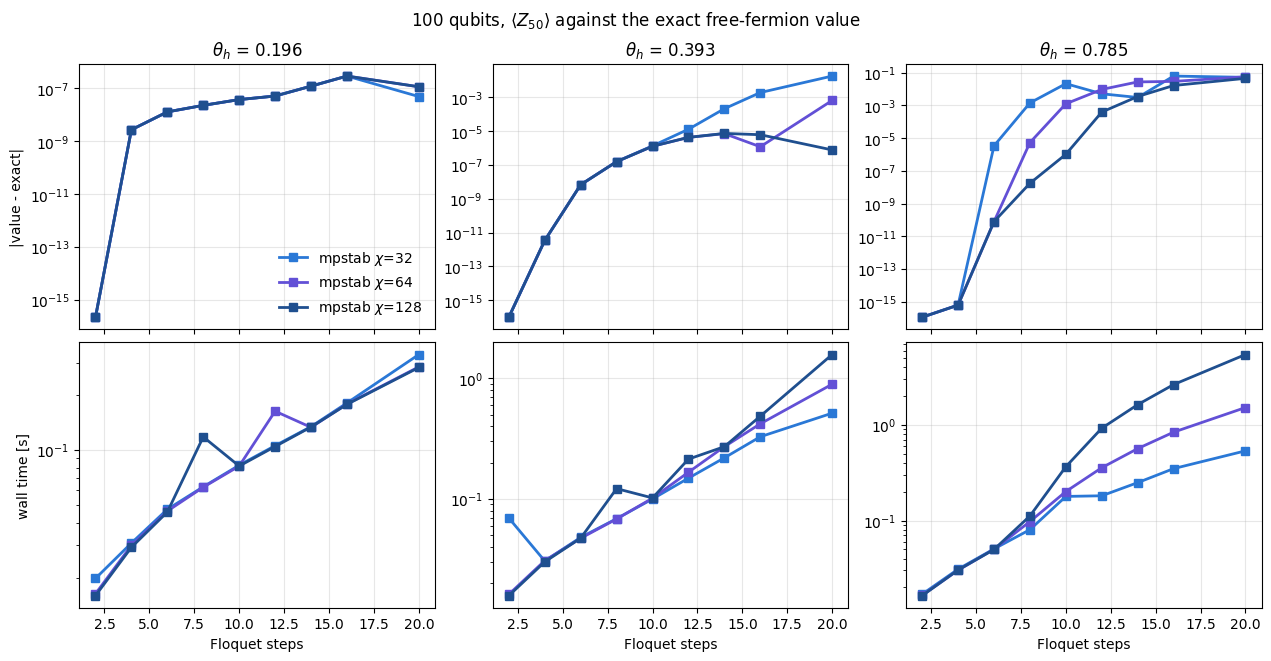

In [4]:
N = 100
STEPS = [2, 4, 6, 8, 10, 12, 14, 16, 20]
THETA_H = [np.pi / 16, np.pi / 8, np.pi / 4]
CHI = [32, 64, 128]
observable = fw.local_z(N, (N // 2,))

rows = []
for theta_h in THETA_H:
    for steps in STEPS:
        circuit = floquet_circuit(N, steps, theta_h)
        reference = exact(covariance_after(circuit), observable)
        for chi in CHI:
            r = fw.run_mpstab(circuit, observable, max_bond=chi)
            rows.append(dict(theta_h=theta_h, steps=steps, chi=chi, exact=reference,
                             error=abs(r["value"] - reference), time=r["time"]))
    print(f"theta_h={theta_h:.3f} done")
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(2, len(THETA_H), figsize=(4.2 * len(THETA_H), 6.5),
                         sharex=True, constrained_layout=True)
for col, theta_h in enumerate(THETA_H):
    for color, chi in zip(COLORS, CHI):
        d = sweep[(sweep.theta_h == theta_h) & (sweep.chi == chi)]
        style = dict(color=color, marker="s", linewidth=2, label=f"mpstab $\\chi$={chi}")
        axes[0, col].plot(d.steps, d.error.clip(lower=1e-16), **style)
        axes[1, col].plot(d.steps, d.time, **style)
    axes[0, col].set(yscale="log", title=f"$\\theta_h$ = {theta_h:.3f}")
    axes[1, col].set(yscale="log", xlabel="Floquet steps")
axes[0, 0].set_ylabel("|value - exact|")
axes[1, 0].set_ylabel("wall time [s]")
for ax in axes.flat:
    ax.grid(alpha=0.3)
axes[0, 0].legend(frameon=False)
fig.suptitle(f"{N} qubits, $\\langle Z_{{{N // 2}}}\\rangle$ against the exact free-fermion value");

At low magic the error sits around $10^{-7}$ whatever $\chi$ is: that is
quimb's default SVD cutoff (singular values below $10^{-10}$ are dropped), not the
bond-dimension cap. With `svd_cutoff=0` the error drops to machine precision, at
the price of keeping every singular value:

In [5]:
circuit = floquet_circuit(N, 8, np.pi / 16)
reference = exact(covariance_after(circuit), observable)
for cutoff in (None, 0.0):
    r = fw.run_mpstab(circuit, observable, max_bond=128, svd_cutoff=cutoff)
    print(f"svd_cutoff={cutoff}: error {abs(r['value'] - reference):.1e}, "
          f"{r['time']:.2f} s, final bond {r['bond']}")

svd_cutoff=None: error 2.2e-08, 0.07 s, final bond 12
svd_cutoff=0.0: error 6.1e-15, 0.15 s, final bond 128


/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


## Pauli propagation on the same target

Each run is a separate Julia process (abandoned after `TIMEOUT` seconds); the
reported time excludes compilation.

    Updating registry at `/private/tmp/claude-501/-Users-robbiati-Documents-PostDoc-mpstab-related-mpstab/d6f12da4-60c4-418f-89df-ec70fe0219f1/scratchpad/julia_depot/registries/General.toml`


     Project No packages added to or removed from `/private/tmp/claude-501/-Users-robbiati-Documents-PostDoc-mpstab-related-mpstab/d6f12da4-60c4-418f-89df-ec70fe0219f1/scratchpad/julia_env/Project.toml`
    Manifest No packages added to or removed from `/private/tmp/claude-501/-Users-robbiati-Documents-PostDoc-mpstab-related-mpstab/d6f12da4-60c4-418f-89df-ec70fe0219f1/scratchpad/julia_env/Manifest.toml`


     Project No packages added to or removed from `/private/tmp/claude-501/-Users-robbiati-Documents-PostDoc-mpstab-related-mpstab/d6f12da4-60c4-418f-89df-ec70fe0219f1/scratchpad/julia_env/Project.toml`
    Manifest No packages added to or removed from `/private/tmp/claude-501/-Users-robbiati-Documents-PostDoc-mpstab-related-mpstab/d6f12da4-60c4-418f-89df-ec70fe0219f1/scratchpad/julia_env/Manifest.toml`


[juliapkg] Found dependencies: /private/tmp/claude-501/-Users-robbiati-Documents-PostDoc-mpstab-related-mpstab/d6f12da4-60c4-418f-89df-ec70fe0219f1/scratchpad/julia_env/pyjuliapkg/juliapkg.json
[juliapkg] Found dependencies: /Users/robbiati/.cache/uv/archive-v0/7Ai9FnySbBq1nKb4NV44c/lib/python3.11/site-packages/juliapkg/juliapkg.json
[juliapkg] Found dependencies: /Users/robbiati/.cache/uv/archive-v0/7Ai9FnySbBq1nKb4NV44c/lib/python3.11/site-packages/juliacall/juliapkg.json
[juliapkg] Locating Julia ^1.10.3
[juliapkg] Querying Julia versions from https://julialang-s3.julialang.org/bin/versions.json
[juliapkg] Using Julia 1.13.4 at /private/tmp/claude-501/-Users-robbiati-Documents-PostDoc-mpstab-related-mpstab/d6f12da4-60c4-418f-89df-ec70fe0219f1/scratchpad/julia_env/pyjuliapkg/install/bin/julia
[juliapkg] Finding libjulia and bindir:
           | using Libdl
           | print(abspath(Libdl.dlpath("libjulia")), '\0', Sys.BINDIR)
[juliapkg] Using shared Julia project at /private/tmp/cla

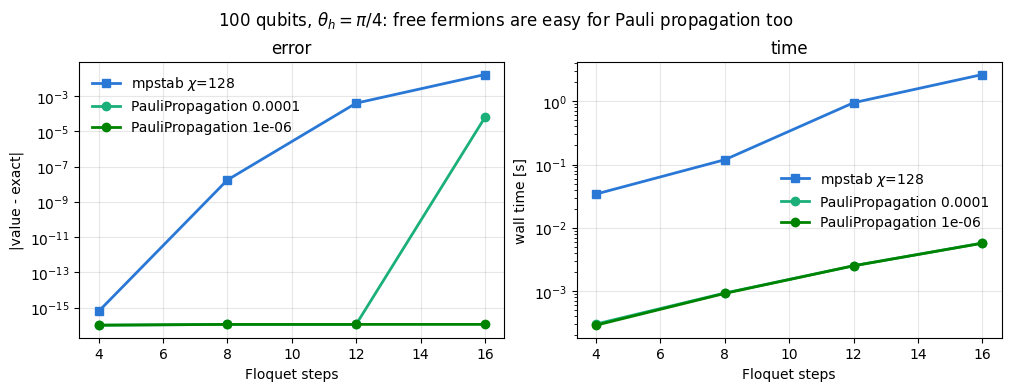

In [6]:
PP_STEPS, PP_THRESHOLDS, TIMEOUT = [4, 8, 12, 16], [1e-4, 1e-6], 120
theta_h = np.pi / 4

pp_rows = []
for steps in PP_STEPS:
    circuit = floquet_circuit(N, steps, theta_h)
    reference = exact(covariance_after(circuit), observable)
    r = fw.run_mpstab(circuit, observable, max_bond=128)
    pp_rows.append(dict(method="mpstab $\\chi$=128", steps=steps,
                        error=abs(r["value"] - reference), time=r["time"]))
    for threshold in PP_THRESHOLDS:
        r = fw.run_pp_isolated(circuit, [], observable, timeout=TIMEOUT,
                               warmup_gates=len(circuit.queue) // steps,
                               min_abs_coeff=threshold)
        if r is not None:
            pp_rows.append(dict(method=f"PauliPropagation {threshold:g}", steps=steps,
                                error=abs(r["value"] - reference), time=r["time"]))
comparison = pd.DataFrame(pp_rows)

fig, (ax_error, ax_time) = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
for color, (method, d) in zip(["#2a78d6", "#1baf7a", "#008300"], comparison.groupby("method", sort=False)):
    style = dict(color=color, marker="s" if "mpstab" in method else "o", linewidth=2, label=method)
    ax_error.plot(d.steps, d.error.clip(lower=1e-16), **style)
    ax_time.plot(d.steps, d.time, **style)
ax_error.set(yscale="log", xlabel="Floquet steps", ylabel="|value - exact|", title="error")
ax_time.set(yscale="log", xlabel="Floquet steps", ylabel="wall time [s]", title="time")
for ax in (ax_error, ax_time):
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
fig.suptitle(f"{N} qubits, $\\theta_h=\\pi/4$: free fermions are easy for Pauli propagation too");